# P2 – Happiness Meter

## What this part does

Spotify's `valence` is a score from 0 to 1 for how **positive** a song sounds (1 = happy, cheerful; 0 = sad, angry, tense). This notebook builds the project's **regression** models: they predict valence from all the *other* audio features, which could auto-tag new songs with a "happiness" score.

In the app this is the **Happiness Meter**: pick a song and see its predicted happiness next to the real value, plus which features push it up or down. The question: *how well does the sound of a song predict how happy it feels, and what does regularization change?* As a bonus we try to predict **popularity** with the same models and explain why that is much harder.

## Concepts in plain English

**Linear regression.** The prediction is a weighted sum of the features plus a constant:

  happiness = w₁·danceability + w₂·energy + … + b

Each weight *w* says how much happiness goes up (positive weight) or down (negative weight) when that feature goes up by one standard deviation (our features are scaled), *holding the other features fixed*.

**Least squares (parameter estimation).** Which weights are best? The ones that make the **sum of squared errors** (predicted − real)² over all training songs as small as possible. Squaring makes big mistakes count more and makes the maths clean: there is a direct formula (the *normal equation*, w = (XᵀX)⁻¹Xᵀy) or we can walk downhill step by step (*gradient descent*). If we assume the errors are random Gaussian (bell-curve) noise, the least-squares weights are exactly the **maximum likelihood** weights: the ones that make the observed data most probable.

**Polynomial features, overfitting and bias–variance.** A straight-line model may be too simple (**high bias**: it misses real curves). Adding squares and pairwise products (energy², energy×danceability, …) lets the model bend, but with many extra weights it can start fitting noise in the training songs (**high variance**: great on training data, worse on new data). That is **overfitting**. The sweet spot balances the two.

**Regularization (Ridge and Lasso).** Add a penalty for large weights to the squared error:
- **Ridge (L2)** penalises the sum of squared weights → shrinks all weights a bit, rarely to exactly zero.
- **Lasso (L1)** penalises the sum of absolute weights → can push weights to **exactly zero**, which drops useless features automatically.
The penalty strength **alpha** is chosen by **cross-validation** (try many alphas, keep the one with the lowest validation error).

**Metrics.**
- **RMSE** (root mean squared error): the typical size of an error, in valence units (0–1).
- **MAE** (mean absolute error): the average size of an error; less sensitive to a few big misses.
- **R²**: the share of the variation in valence that the model explains. 1 = perfect, 0 = no better than always guessing the average, negative = worse than guessing the average.

## Setup
Load the shared split. **Valence is removed from the inputs**, since it is what we predict.

In [1]:
import sys, json
sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, KFold

from src import data, evaluate
from src.style import GENRE_COLORS, setup_notebook_style

np.random.seed(42)
setup_notebook_style()
pd.set_option("display.width", 140, "display.precision", 3)
FIG = data.ROOT / "results" / "figures" / "p2_happiness"
MODELS = data.ROOT / "models" / "p2_happiness"
FIG.mkdir(parents=True, exist_ok=True); MODELS.mkdir(parents=True, exist_ok=True)

X_train, X_test, y_train, y_test, feature_names = data.load_splits()
Xtr, Xte = X_train.drop(columns="valence"), X_test.drop(columns="valence")
ytr, yte = y_train["valence"], y_test["valence"]
print("Inputs:", Xtr.shape[1], "features (valence removed).  Train songs:", len(Xtr), " Test songs:", len(Xte))
print("Valence in training songs: mean %.3f, std %.3f" % (ytr.mean(), ytr.std()))

Inputs: 25 features (valence removed).  Train songs: 3413  Test songs: 854
Valence in training songs: mean 0.448, std 0.230


## 1. The four models
- **Linear regression**: plain least squares on the 25 features.
- **Polynomial (degree 2) + linear regression**: adds all squares and pairwise products (25 → 350 features).
- **RidgeCV**: linear regression with an L2 penalty; alpha picked from 50 values by 5-fold cross-validation.
- **LassoCV**: linear regression with an L1 penalty; alpha picked by 5-fold cross-validation.

To decide which model is "best" we use **5-fold cross-validation on the training set only** (the test set is touched once per model at the end).

In [2]:
cv = KFold(5, shuffle=True, random_state=42)
models = {
    "Linear regression": LinearRegression(),
    "Polynomial (deg 2) + linear": make_pipeline(PolynomialFeatures(2, include_bias=False), LinearRegression()),
    "Ridge (RidgeCV)": RidgeCV(alphas=np.logspace(-3, 4, 50), cv=cv),
    "Lasso (LassoCV)": LassoCV(alphas=np.logspace(-5, 0, 50), cv=cv, random_state=42, max_iter=20000),
}
rows = []
for name, m in models.items():
    cv_r2 = cross_val_score(m, Xtr, ytr, cv=cv, scoring="r2").mean()
    m.fit(Xtr, ytr)
    train_r2 = evaluate.regression_metrics(ytr, m.predict(Xtr))["r2"]
    test = evaluate.regression_metrics(yte, m.predict(Xte))
    evaluate.log_score("P2 Happiness Meter", name, "valence", test)
    evaluate.save_predictions("valence", name, Xte.index, m.predict(Xte), y_true=yte)
    rows.append({"model": name, "train R²": train_r2, "CV R² (train)": cv_r2, **{f"test {k.upper() if k!='r2' else 'R²'}": v for k, v in test.items()}})
results = pd.DataFrame(rows).set_index("model")
print("Ridge alpha chosen by CV:", models["Ridge (RidgeCV)"].alpha_)
print("Lasso alpha chosen by CV: %.5f" % models["Lasso (LassoCV)"].alpha_)
results.round(3)

Ridge alpha chosen by CV: 5.179474679231207
Lasso alpha chosen by CV: 0.00087


,train R²,CV R² (train),test RMSE,test MAE,test R²
model,,,,,
Linear regression,0.311,0.296,0.188,0.150,0.295
Polynomial (deg 2) + linear,0.436,0.286,0.212,0.153,0.104
Ridge (RidgeCV),0.311,0.296,0.188,0.150,0.295
Lasso (LassoCV),0.311,0.297,0.188,0.150,0.295


This shows that the three linear models (plain, Ridge, Lasso) are practically identical: **test R² ≈ 0.30, RMSE ≈ 0.19** (on a 0–1 scale where valence has a spread of 0.23). With 3,400 songs and only 25 features there is little overfitting for regularization to fix, so CV picked only mild penalties (Ridge alpha ≈ 5, Lasso alpha ≈ 0.0009). The **polynomial model is the clear loser on test data (R² 0.10)** even though it fits the training songs best (0.44): classic overfitting.

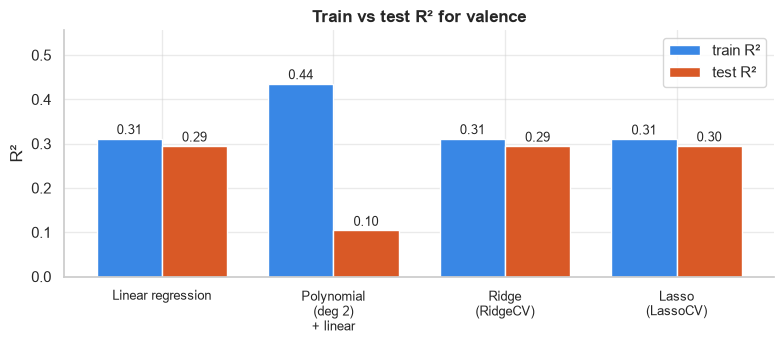

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.6))
idx = np.arange(len(results)); w = 0.38
ax.bar(idx - w/2, results["train R²"], w, label="train R²", color="#3987e5")
ax.bar(idx + w/2, results["test R²"], w, label="test R²", color="#d95926")
for i, (a, b) in enumerate(zip(results["train R²"], results["test R²"])):
    ax.text(i - w/2, a + .01, f"{a:.2f}", ha="center", fontsize=9); ax.text(i + w/2, b + .01, f"{b:.2f}", ha="center", fontsize=9)
ax.set_xticks(idx, [n.replace(" + ", "\n+ ").replace(" (", "\n(") for n in results.index], fontsize=9)
ax.set_ylabel("R²"); ax.set_title("Train vs test R² for valence"); ax.legend(loc="upper right")
ax.set_ylim(0, max(results["train R²"]) + .12)
plt.tight_layout(); plt.savefig(FIG / "train_vs_test_r2.png", dpi=120); plt.show()

This shows bias–variance in one picture. The linear models score the same on train and test (0.31 vs 0.30): low variance, but they cannot capture everything (some bias). The polynomial model's 350 features let it memorise training songs (train R² 0.44) but it generalises much worse (test 0.10): **high variance / overfitting**.

## 2. What makes a song sound happy? (the weights)
The bar chart shows the weights of the plain linear regression and Ridge, side by side. Because every feature is scaled, the weights are directly comparable: a weight of +0.05 means "one standard deviation more of this feature → valence about 0.05 higher".

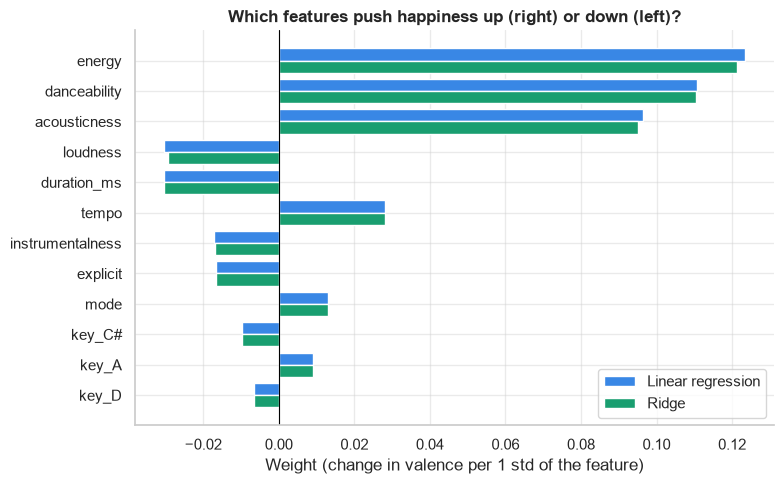

,Linear regression,Ridge,Lasso
energy,0.123,0.121,0.110
danceability,0.111,0.110,0.108
acousticness,0.097,0.095,0.089
loudness,-0.030,-0.029,-0.020
duration_ms,-0.030,-0.030,-0.030
tempo,0.028,0.028,0.027
instrumentalness,-0.017,-0.017,-0.013
explicit,-0.017,-0.017,-0.016
mode,0.013,0.013,0.012
key_C#,-0.010,-0.010,-0.008


In [4]:
coefs = pd.DataFrame({"Linear regression": models["Linear regression"].coef_,
                      "Ridge": models["Ridge (RidgeCV)"].coef_,
                      "Lasso": models["Lasso (LassoCV)"].coef_}, index=Xtr.columns)
top = coefs["Linear regression"].abs().sort_values(ascending=False).index[:12]
fig, ax = plt.subplots(figsize=(8, 5))
y = np.arange(len(top))
ax.barh(y - .2, coefs.loc[top, "Linear regression"], .4, color="#3987e5", label="Linear regression")
ax.barh(y + .2, coefs.loc[top, "Ridge"], .4, color="#199e70", label="Ridge")
ax.set_yticks(y, top); ax.invert_yaxis(); ax.axvline(0, color="black", lw=.8)
ax.set_xlabel("Weight (change in valence per 1 std of the feature)")
ax.set_title("Which features push happiness up (right) or down (left)?"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "coefficients.png", dpi=120); plt.show()
coefs.loc[top].round(4)

This shows that **danceability (+0.11) and energy (+0.12)** are the strongest "happy" features: lively, danceable songs sound more positive. Surprisingly **acousticness is also positive (+0.10)** once energy is held fixed: among songs with the same energy, acoustic ones (e.g. upbeat country or folk-like jazz) sound happier than electronic or distorted ones. Loudness, long duration, instrumentalness and explicit lyrics push happiness slightly down; the musical key barely matters (all key weights are below 0.01). Ridge's weights are only a touch smaller than plain regression's, matching its small alpha.

## 3. Which features did Lasso drop?
Lasso's L1 penalty pushes weak weights to exactly zero.

In [5]:
dropped = coefs.index[coefs["Lasso"] == 0].tolist()
print(f"Lasso set {len(dropped)} of {len(coefs)} weights to exactly zero:")
print(dropped)
print("\nRidge weights set to zero:", int((coefs['Ridge'] == 0).sum()), "(Ridge shrinks but does not zero)")

Lasso set 3 of 25 weights to exactly zero:
['key_F', 'key_B', 'time_sig_5']

Ridge weights set to zero: 0 (Ridge shrinks but does not zero)


This shows Lasso dropped **3 features: key F, key B and the 5/4 time signature**. They carry almost no information about happiness, so Lasso removes them entirely. Ridge never sets weights exactly to zero; it only shrinks them. With a stronger alpha Lasso would drop more, but cross-validation found that the small alpha predicts best.

## 4. Predicted vs actual valence
Each dot is a test song. Perfect predictions would lie on the dashed diagonal.

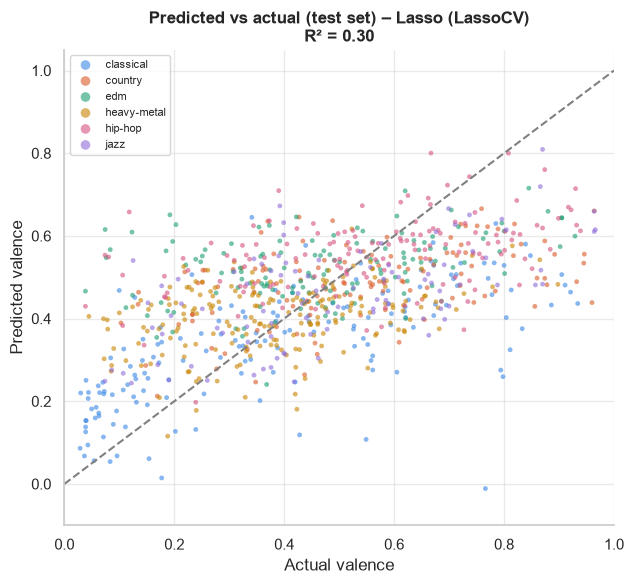

Best model by cross-validation on the training set: Lasso (LassoCV)


In [6]:
best_name = results["CV R² (train)"].idxmax()
best = models[best_name]
pred = best.predict(Xte)
songs, _ = data.load_all_songs()
g = songs.loc[Xte.index, "track_genre"]
fig, ax = plt.subplots(figsize=(6.5, 6))
for genre in data.GENRES:
    m = (g == genre).values
    ax.scatter(yte[m], pred[m], s=12, alpha=.6, color=GENRE_COLORS[genre], label=genre, edgecolors="none")
ax.plot([0, 1], [0, 1], "--", color="gray"); ax.set_xlim(0, 1); ax.set_ylim(-0.1, 1.05)
ax.set_xlabel("Actual valence"); ax.set_ylabel("Predicted valence")
ax.set_title(f"Predicted vs actual (test set) – {best_name}\nR² = {results.loc[best_name, 'test R²']:.2f}")
ax.legend(markerscale=2, fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "predicted_vs_actual.png", dpi=120); plt.show()
print("Best model by cross-validation on the training set:", best_name)

This shows the model gets the **trend** right (dots rise from left to right; very sad classical songs at the bottom left are well predicted) but predictions are **squeezed towards the middle** (mostly 0.2–0.7): it rarely dares to predict a very happy or very sad song. That is typical of a model with R² ≈ 0.3. Plenty of happiness is decided by things that audio features don't measure, such as lyrics and harmony.

## 5. Bonus: can the same models predict popularity?
Same four models, same features (this time valence *is* an input, and popularity is the target; popularity is never an input anywhere else).

In [7]:
ptr, pte = y_train["popularity"], y_test["popularity"]
pop_models = {
    "Linear regression": LinearRegression(),
    "Polynomial (deg 2) + linear": make_pipeline(PolynomialFeatures(2, include_bias=False), LinearRegression()),
    "Ridge (RidgeCV)": RidgeCV(alphas=np.logspace(-3, 4, 50), cv=cv),
    "Lasso (LassoCV)": LassoCV(alphas=np.logspace(-4, 1, 50), cv=cv, random_state=42, max_iter=20000),
}
prow = []
for name, m in pop_models.items():
    m.fit(X_train, ptr)
    test = evaluate.regression_metrics(pte, m.predict(X_test))
    evaluate.log_score("P2 Happiness Meter", name, "popularity", test)
    prow.append({"model": name, "train R²": evaluate.regression_metrics(ptr, m.predict(X_train))["r2"],
                 "test RMSE": test["rmse"], "test MAE": test["mae"], "test R²": test["r2"]})
pop_results = pd.DataFrame(prow).set_index("model")
compare = pd.DataFrame({"valence test R²": results["test R²"], "popularity test R²": pop_results["test R²"]})
display(pop_results.round(3)); compare.round(3)

,train R²,test RMSE,test MAE,test R²
model,,,,
Linear regression,0.172,25.022,20.688,0.103
Polynomial (deg 2) + linear,0.275,25.194,20.071,0.090
Ridge (RidgeCV),0.172,24.978,20.719,0.106
Lasso (LassoCV),0.171,24.961,20.716,0.107


,valence test R²,popularity test R²
model,,
Linear regression,0.295,0.103
Polynomial (deg 2) + linear,0.104,0.090
Ridge (RidgeCV),0.295,0.106
Lasso (LassoCV),0.295,0.107


This shows that popularity is much harder: the best **test R² is only 0.11** (vs 0.30 for valence) and the typical error is about **25 popularity points** on a 0–100 scale. Most of the small R² that exists comes from genre-level differences (some genres are simply more streamed on average), not from what makes an individual song popular. Again the polynomial model overfits (train 0.28 → test 0.09).

## 6. Save the models for the app
- `valence_best.joblib`: the best model by cross-validation, used for the predicted happiness.
- `valence_ridge.joblib`: the Ridge model, used in the app to explain *why* (each feature's weight × the song's value).

In [8]:
joblib.dump({"model": best, "name": best_name, "features": list(Xtr.columns)}, MODELS / "valence_best.joblib")
joblib.dump({"model": models["Ridge (RidgeCV)"], "name": "Ridge (RidgeCV)", "features": list(Xtr.columns)},
            MODELS / "valence_ridge.joblib")
print("Saved:", sorted(p.name for p in MODELS.iterdir()))

Saved: ['valence_best.joblib', 'valence_ridge.joblib']


## 7. Built from scratch: least squares with NumPy
`src/scratch.py` implements linear regression ourselves in two ways: the **normal equation** w = (XᵀX)⁻¹Xᵀy (one direct calculation) and **gradient descent** (start with all weights at 0 and repeatedly step downhill along the gradient of the mean squared error). Both should match scikit-learn's `LinearRegression`.

Largest weight difference, normal equation vs scikit-learn: 1.42e-15
Largest weight difference, gradient descent vs scikit-learn: 1.42e-15


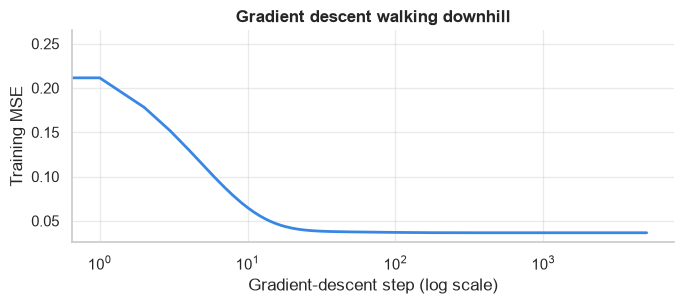

,scikit-learn,scratch: normal equation,scratch: gradient descent
test R²,0.295,0.295,0.295
intercept,0.448,0.448,0.448
weight: energy,0.123,0.123,0.123


In [9]:
from src.scratch import LinearRegressionScratch
from sklearn.metrics import r2_score
ne = LinearRegressionScratch("normal").fit(Xtr, ytr)
gd = LinearRegressionScratch("gd", lr=0.05, n_iter=5000).fit(Xtr, ytr)
sk = models["Linear regression"]
cmp = pd.DataFrame({
    "scikit-learn": {"test R²": r2_score(yte, sk.predict(Xte)), "intercept": sk.intercept_, "weight: energy": sk.coef_[list(Xtr.columns).index("energy")]},
    "scratch: normal equation": {"test R²": r2_score(yte, ne.predict(Xte)), "intercept": ne.intercept_, "weight: energy": ne.coef_[list(Xtr.columns).index("energy")]},
    "scratch: gradient descent": {"test R²": r2_score(yte, gd.predict(Xte)), "intercept": gd.intercept_, "weight: energy": gd.coef_[list(Xtr.columns).index("energy")]},
})
print("Largest weight difference, normal equation vs scikit-learn: %.2e" % np.abs(ne.coef_ - sk.coef_).max())
print("Largest weight difference, gradient descent vs scikit-learn: %.2e" % np.abs(gd.coef_ - sk.coef_).max())
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(gd.loss_history_, color="#3987e5", lw=2); ax.set_xscale("log")
ax.set_xlabel("Gradient-descent step (log scale)"); ax.set_ylabel("Training MSE"); ax.set_title("Gradient descent walking downhill")
plt.tight_layout(); plt.savefig(FIG / "scratch_gradient_descent.png", dpi=120); plt.show()
cmp.round(5)

This shows both from-scratch versions give **the same model as scikit-learn** (test R² 0.2947, identical intercept and weights to many decimal places). Gradient descent's loss drops quickly in the first ~100 steps and then flattens at the least-squares minimum: the step-by-step method arrives at the same answer the normal equation computes in one go.

## Results summary

| Model | Test RMSE (valence) | Test MAE | Test R² (valence) | Test R² (popularity) |
|---|---|---|---|---|
| Linear regression | 0.188 | 0.150 | 0.295 | 0.103 |
| Polynomial (deg 2) + linear | 0.212 | 0.153 | 0.104 | 0.090 |
| Ridge (alpha ≈ 5.2) | 0.188 | 0.150 | 0.295 | 0.106 |
| Lasso (alpha ≈ 0.0009) | 0.188 | 0.150 | 0.295 | 0.107 |
| *Baseline: always predict the mean* | *0.224* | *0.184* | *0.00* | *0.00* |

**Takeaways**
- Sound explains about **30% of happiness**: clearly better than guessing, but lyrics and harmony matter too.
- **Danceability and energy make songs sound happier**; the musical key hardly matters.
- **Polynomial features overfit** (train R² 0.44 → test 0.10): more flexibility is not always better.
- Ridge and Lasso barely change the result because the plain model was not overfitting; Lasso still drops 3 useless features (key F, key B, 5/4 time).
- **Popularity is much harder (R² ≈ 0.1)**: it depends on fame and marketing, not just sound.

## Questions you may be asked

**1. What does R² = 0.4 mean in plain words?**
The model explains 40% of the differences in happiness between songs; the other 60% comes from things our features don't capture (lyrics, harmony, production) or from noise. It is clearly better than always guessing the average song (R² = 0), but far from perfect (R² = 1).

**2. What is the difference between L1 and L2, and why does Lasso set weights to zero?**
L2 (Ridge) penalises squared weights: the penalty barely grows for small weights, so it shrinks everything a little but rarely to zero. L1 (Lasso) penalises absolute weights: even a tiny weight costs a fixed amount per unit, so for a weak feature it is "cheaper" to set the weight exactly to zero than to keep a small value. Geometrically, the L1 constraint is a diamond with corners on the axes, and the best solution often lands on a corner where some weights are 0.

**3. What assumptions does linear regression make?**
(1) The relationship between features and target is linear (a weighted sum); (2) errors are independent of each other; (3) errors have roughly constant spread (homoscedasticity); (4) for the least-squares = maximum-likelihood link and for confidence intervals, errors are roughly Gaussian; (5) features are not perfectly collinear (that is why one key column is dropped). In our data, (1) is only partly true (the MLP in P6 does slightly better, R² 0.32), but adding polynomial features did not help: with 350 extra columns they overfit (test R² 0.10).

**4. Why is popularity so much harder to predict than valence?**
Valence is a property of the sound itself (it was computed from the audio), so audio features carry a lot of information about it. Popularity depends on things that are not in the audio: the artist's fame, marketing, playlists, release date, social media and luck. Two songs with identical features can have popularity 5 and 85. Our test R² of about 0.1 (vs 0.3 for valence) shows this, and even that small amount mostly reflects that some genres are more streamed than others.

**5. How did you pick alpha?**
By 5-fold cross-validation on the training set: RidgeCV tried 50 alphas between 0.001 and 10,000, LassoCV 50 between 0.00001 and 1. For each alpha the training set is split into 5 parts; the model is trained on 4 and tested on the 5th, five times, and the alpha with the best average validation score wins (Ridge ≈ 5.2, Lasso ≈ 0.0009). The test set was never used to choose alpha.